In [106]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Grafik ayarları
%matplotlib inline
sns.set(style="whitegrid")

In [107]:
filePath = 'used_cars 3.csv'
df = pd.read_csv(filePath)

In [108]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [109]:
# Veri setindeki satır ve sütun sayılarını öğrenme
df.shape


(4009, 12)

In [110]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB


,model_year
count,4009.000000
mean,2015.515590
std,6.104816
min,1974.000000
25%,2012.000000
50%,2017.000000
75%,2020.000000
max,2024.000000


In [111]:
# Eksik veri olup olmadığının kontrol edilmesi
print(df.isnull().sum())

brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64


In [112]:
df_original = df.copy()
df_processed = df.copy()

In [113]:
#price temizleme
df_processed['price'] = df_processed['price'].str.replace('$', '')
df_processed['price'] = df_processed['price'].str.replace(',', '')
df_processed['price'] = df_processed['price'].astype(int)

In [114]:
# milage temizleme
df_processed['milage'] = df_processed['milage'].str.replace(' mi.', '')
df_processed['milage'] = df_processed['milage'].str.replace(',', '')
df_processed['milage'] = df_processed['milage'].astype(int)


In [115]:
df_processed.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300
1,Hyundai,Palisade SEL,2021,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005
2,Lexus,RX 350 RX 350,2022,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598
3,INFINITI,Q50 Hybrid Sport,2015,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500
4,Audi,Q3 45 S line Premium Plus,2021,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999


In [116]:
# Eksik veri olup olmadığının kontrol edilmesi
print(df.isnull().sum())

brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64


In [117]:
most_common_fuel = df_processed['fuel_type'].mode()[0]  # sütundaki en sık bulunan fueltype değeri aldık
df_processed['fuel_type'] = df_processed['fuel_type'].fillna(most_common_fuel) # eksik değerleri en sık değerle doldurduk

In [118]:
print(df_processed['fuel_type'].isnull().sum())  # eksik değer kalmadığını kontrol ediyorım


0


In [119]:
# Eksik veri olup olmadığının kontrol edilmesi
print(df_processed.isnull().sum())

brand             0
model             0
model_year        0
milage            0
fuel_type         0
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64


In [120]:
df_processed['accident'] = df_processed['accident'].fillna('No data')

In [121]:
print(df_processed['accident'].isnull().sum())  # eksik değer kalmadığını kontrol ediyorım

0


In [122]:
# Eksik veri olup olmadığının kontrol edilmesi
print(df_processed.isnull().sum())

brand             0
model             0
model_year        0
milage            0
fuel_type         0
engine            0
transmission      0
ext_col           0
int_col           0
accident          0
clean_title     596
price             0
dtype: int64


In [123]:
#boş clean titleları accident ile doldurma (kazası varsa cleantitle=false, kazası yoksa cleantitle=true)
mask = df_processed['clean_title'].isna()
df_processed.loc[mask & (df_processed['accident'] == "At least 1 accident or damage reported"), 'clean_title'] = "No"
df_processed.loc[mask & (df_processed['accident'] == "None reported"), 'clean_title'] = "Yes"
df_processed.loc[mask & (df_processed['accident'] == "No data"), 'clean_title'] = "None"

In [124]:
# Eksik veri olup olmadığının kontrol edilmesi
print(df_processed.isnull().sum())

brand           0
model           0
model_year      0
milage          0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
dtype: int64


In [125]:
df_processed.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300
1,Hyundai,Palisade SEL,2021,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005
2,Lexus,RX 350 RX 350,2022,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,Yes,54598
3,INFINITI,Q50 Hybrid Sport,2015,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500
4,Audi,Q3 45 S line Premium Plus,2021,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,Yes,34999


In [126]:
# car_age oluşturoruz ve model_year dropluyoruz
df_processed['car_age'] = 2026 - df_processed['model_year']
df_processed.drop(columns=['model_year'], inplace=True)

In [127]:
df_processed.head()

,brand,model,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,car_age
0,Ford,Utility Police Interceptor Base,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300,13
1,Hyundai,Palisade SEL,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005,5
2,Lexus,RX 350 RX 350,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,Yes,54598,4
3,INFINITI,Q50 Hybrid Sport,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500,11
4,Audi,Q3 45 S line Premium Plus,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,Yes,34999,5


In [128]:
# fuel_type basitleştirme
fuel_map = {
    'Electric': 'Electric',
    'E85 Flex Fuel': 'FlexFuel',
    'Gasoline': 'Gasoline',
    'Hybrid': 'Hybrid',
    'Plug-In Hybrid': 'Hybrid'
}
df_processed['fuel_type'] = df_processed['fuel_type'].map(fuel_map).fillna('Others')

In [129]:
df_processed.head()

,brand,model,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,car_age
0,Ford,Utility Police Interceptor Base,51000,FlexFuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300,13
1,Hyundai,Palisade SEL,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005,5
2,Lexus,RX 350 RX 350,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,Yes,54598,4
3,INFINITI,Q50 Hybrid Sport,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500,11
4,Audi,Q3 45 S line Premium Plus,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,Yes,34999,5


In [130]:

# hp sütunu oluşturuyorum: ör 300.0
df_processed['hp'] = df_processed['engine'].str.extract(r'(\d+\.\d+)HP').astype(float, errors='ignore')

# motor hacmi (engine displacement) sütunu oluşturuyorum: ör 3.5
df_processed['engine displacement'] = df_processed['engine'].str.extract(r'(\d+\.\d+)\s*L')
df_processed['engine displacement'] = df_processed['engine displacement'].fillna(df['engine'].str.extract(r'(\d+\.\d+)\s*LITER')[0])
df_processed['engine displacement'] = df_processed['engine displacement'].astype(float, errors='ignore')

# V tipi motor mu? v tipi ise true,değilse false
df_processed['is_v_engine'] = df_processed['engine'].str.contains(r'V\d+', case=False, na=False)

# Turbo motor var mı? varsa true, yoksa false
df_processed['turbo'] = df_processed['engine'].str.contains('TWIN TURBO', case=False, na=False)

# DOHC var mı? varsa true, yoksa false
df_processed['dohc'] = df_processed['engine'].str.contains('DOHC', case=False, na=False)

df_processed.drop(columns=['engine'], inplace=True)


In [131]:
df_processed.head()

,brand,model,milage,fuel_type,transmission,ext_col,int_col,accident,clean_title,price,car_age,hp,engine displacement,is_v_engine,turbo,dohc
0,Ford,Utility Police Interceptor Base,51000,FlexFuel,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300,13,300.0,3.7,True,False,False
1,Hyundai,Palisade SEL,34742,Gasoline,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005,5,NaN,3.8,True,False,True
2,Lexus,RX 350 RX 350,22372,Gasoline,Automatic,Blue,Black,None reported,Yes,54598,4,NaN,3.5,False,False,True
3,INFINITI,Q50 Hybrid Sport,88900,Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500,11,354.0,3.5,True,False,False
4,Audi,Q3 45 S line Premium Plus,9835,Gasoline,8-Speed Automatic,Glacier White Metallic,Black,None reported,Yes,34999,5,NaN,2.0,False,False,True


In [132]:
def classify_trans(x):
    x = str(x).lower()
    if "manual" in x or "m/t" in x or ("mt" in x and "auto" not in x):
        return "MT"
    elif "cvt" in x:
        return "CVT"
    elif "amt" in x or "auto manual" in x or "ag" in x or "imt" in x:
        return "AMT"
    elif "auto" in x or "a/t" in x or "automatic" in x:
        return "AT"
    else:
        return "Others"
df_processed['transmission_clean'] = df_processed['transmission'].apply(classify_trans)

df_processed.drop(columns=['transmission'], inplace=True)


In [133]:
df_processed['transmission_clean'].unique()

array(['AT', 'Others', 'MT', 'CVT'], dtype=object)

In [134]:
# Renkleri ayrıştırma
def map_color(color):
    color = str(color).lower()
    if any(w in color for w in ['white', 'diamond', 'ivory', 'snow', 'pearl']):
        return 'White'
    elif any(w in color for w in ['black', 'jet black', 'onyx', 'obsidian', 'ebony']):
        return 'Black'
    elif any(w in color for w in ['blue', 'blu', 'navy', 'aqua', 'azure']):
        return 'Blue'
    elif any(w in color for w in ['red', 'burgundy', 'maroon']):
        return 'Red'
    elif any(w in color for w in ['silver', 'grey', 'gray', 'graphite', 'metal', 'granite']):
        return 'Silver/Gray'
    elif any(w in color for w in ['green', 'olive']):
        return 'Green'
    elif any(w in color for w in ['brown', 'bronze', 'beige']):
        return 'Brown'
    elif any(w in color for w in ['gold', 'sand', 'champagne']):
        return 'Gold/Beige'
    elif any(w in color for w in ['orange', 'yellow', 'tan']):
        return 'Orange/Yellow'
    else:
        return 'Other'

df_processed['exterior_color'] = df_processed['ext_col'].apply(map_color)
df_processed['interior_color'] = df_processed['int_col'].apply(map_color)

df_processed.drop(columns=['ext_col', 'int_col'], inplace=True)

In [135]:
df_processed.head()

,brand,model,milage,fuel_type,accident,clean_title,price,car_age,hp,engine displacement,is_v_engine,turbo,dohc,transmission_clean,exterior_color,interior_color
0,Ford,Utility Police Interceptor Base,51000,FlexFuel,At least 1 accident or damage reported,Yes,10300,13,300.0,3.7,True,False,False,AT,Black,Black
1,Hyundai,Palisade SEL,34742,Gasoline,At least 1 accident or damage reported,Yes,38005,5,NaN,3.8,True,False,True,AT,Other,Silver/Gray
2,Lexus,RX 350 RX 350,22372,Gasoline,None reported,Yes,54598,4,NaN,3.5,False,False,True,AT,Blue,Black
3,INFINITI,Q50 Hybrid Sport,88900,Hybrid,None reported,Yes,15500,11,354.0,3.5,True,False,False,AT,Black,Black
4,Audi,Q3 45 S line Premium Plus,9835,Gasoline,None reported,Yes,34999,5,NaN,2.0,False,False,True,AT,White,Black


In [136]:
# Eksik veri olup olmadığının kontrol edilmesi
print(df_processed.isnull().sum())

brand                    0
model                    0
milage                   0
fuel_type                0
accident                 0
clean_title              0
price                    0
car_age                  0
hp                     810
engine displacement    236
is_v_engine              0
turbo                    0
dohc                     0
transmission_clean       0
exterior_color           0
interior_color           0
dtype: int64


In [137]:
# hp sütunundaki eksik verileri her bir markanın kendi ortalaması ile dolduruyoruz ve hala eksik veri varsa o satırları siliyoruz
df_processed['hp'] = df_processed.groupby('brand')['hp'].transform(lambda x: x.fillna(x.mean()))
df_processed.dropna(subset=['hp'], inplace=True)
print(df_processed.isnull().sum())

brand                    0
model                    0
milage                   0
fuel_type                0
accident                 0
clean_title              0
price                    0
car_age                  0
hp                       0
engine displacement    235
is_v_engine              0
turbo                    0
dohc                     0
transmission_clean       0
exterior_color           0
interior_color           0
dtype: int64


In [138]:
most_common_displacement = df_processed.groupby('brand')['engine displacement'].agg(lambda x: x.mode()[0] if not x.mode().empty else None)

df_processed['engine displacement'] = df_processed.apply(
    lambda row: most_common_displacement[row['brand']] if pd.isna(row['engine displacement']) else row['engine displacement'],
    axis=1
)

df_processed['engine displacement'] = df_processed['engine displacement'].fillna(df_processed['engine displacement'].median())

print(df_processed.isnull().sum())


brand                  0
model                  0
milage                 0
fuel_type              0
accident               0
clean_title            0
price                  0
car_age                0
hp                     0
engine displacement    0
is_v_engine            0
turbo                  0
dohc                   0
transmission_clean     0
exterior_color         0
interior_color         0
dtype: int64


In [139]:
df_processed.info()
df_processed.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 4007 entries, 0 to 4008
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brand                4007 non-null   object 
 1   model                4007 non-null   object 
 2   milage               4007 non-null   int64  
 3   fuel_type            4007 non-null   object 
 4   accident             4007 non-null   object 
 5   clean_title          4007 non-null   object 
 6   price                4007 non-null   int64  
 7   car_age              4007 non-null   int64  
 8   hp                   4007 non-null   float64
 9   engine displacement  4007 non-null   float64
 10  is_v_engine          4007 non-null   bool   
 11  turbo                4007 non-null   bool   
 12  dohc                 4007 non-null   bool   
 13  transmission_clean   4007 non-null   object 
 14  exterior_color       4007 non-null   object 
 15  interior_color       4007 non-null   object

,milage,price,car_age,hp,engine displacement
count,4007.000000,4.007000e+03,4007.000000,4007.000000,4007.000000
mean,64745.235837,4.407955e+04,10.484652,332.359263,3.678450
std,52294.920810,7.273888e+04,6.105308,115.308015,1.393088
min,100.000000,2.000000e+03,2.000000,70.000000,0.650000
25%,23090.000000,1.715000e+04,6.000000,252.404040,2.500000
50%,53000.000000,3.100000e+04,9.000000,320.000000,3.500000
75%,94127.500000,4.997000e+04,14.000000,385.000000,4.600000
max,405000.000000,2.954083e+06,52.000000,1020.000000,8.400000


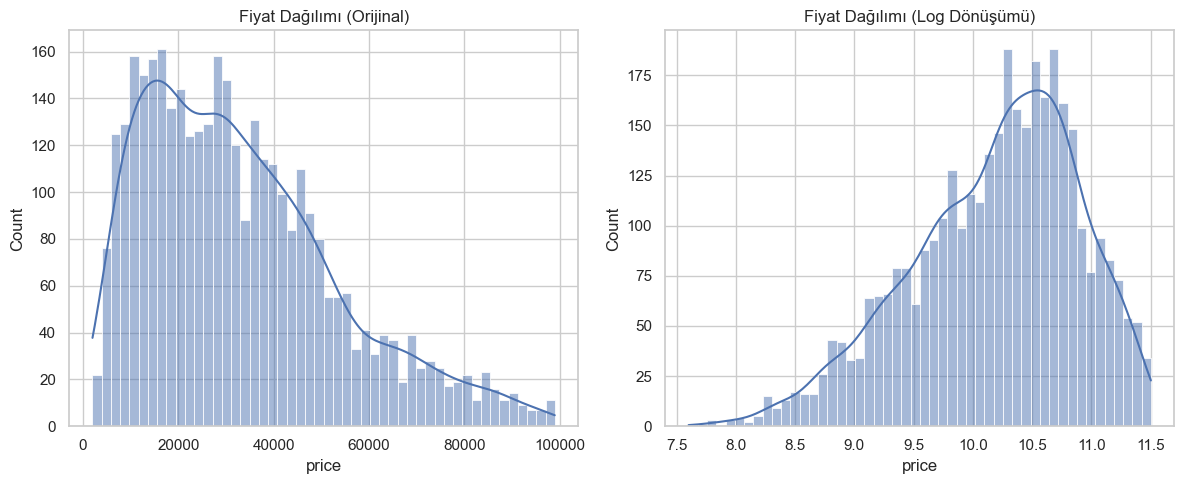

In [185]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_processed['price'], bins=50, kde=True)
plt.title("Fiyat Dağılımı (Orijinal)")

plt.subplot(1, 2, 2)
sns.histplot(np.log1p(df_processed['price']), bins=50, kde=True)
plt.title("Fiyat Dağılımı (Log Dönüşümü)")

plt.tight_layout()
plt.show()


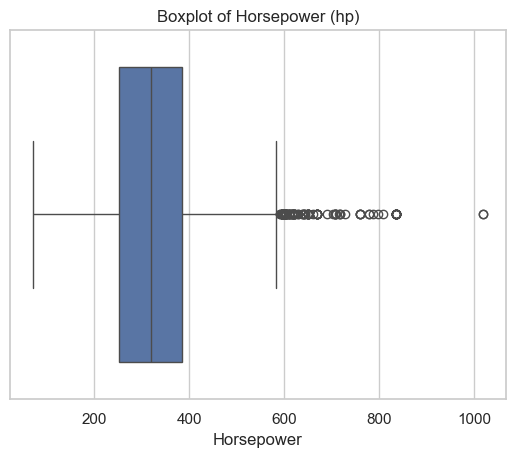

In [140]:
sns.boxplot(x=df_processed['hp'])

plt.title("Boxplot of Horsepower (hp)")
plt.xlabel("Horsepower")
plt.show()

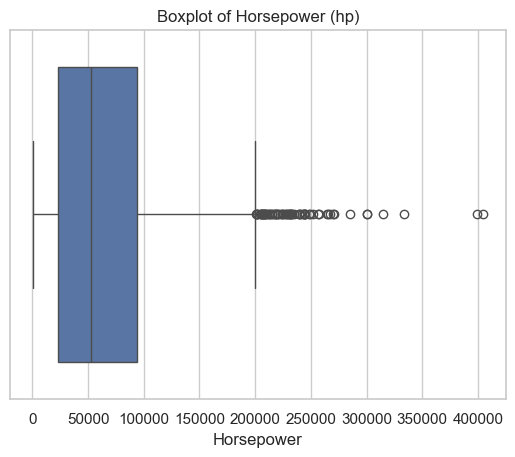

In [141]:
sns.boxplot(x=df_processed['milage'])

plt.title("Boxplot of Horsepower (hp)")
plt.xlabel("Horsepower")
plt.show()

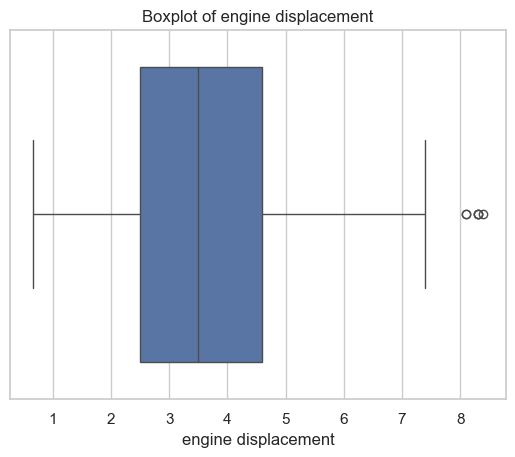

In [142]:
sns.boxplot(x=df_processed['engine displacement'])

plt.title("Boxplot of engine displacement")
plt.xlabel("engine displacement")
plt.show()

In [143]:
Q1 = df_processed['engine displacement'].quantile(0.25)
Q3 = df_processed['engine displacement'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_processed = df_processed[(df_processed['engine displacement'] >= lower_bound) & (df_processed['engine displacement'] <= upper_bound)]

In [144]:
Q1 = df_processed['price'].quantile(0.25)
Q3 = df_processed['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_processed = df_processed[(df_processed['price'] >= lower_bound) & (df_processed['price'] <= upper_bound)]

In [145]:
Q1 = df_processed['milage'].quantile(0.25)
Q3 = df_processed['milage'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_processed = df_processed[(df_processed['milage'] >= lower_bound) & (df_processed['milage'] <= upper_bound)]

In [146]:
Q1 = df_processed['hp'].quantile(0.25)
Q3 = df_processed['hp'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_processed = df_processed[(df_processed['hp'] >= lower_bound) & (df_processed['hp'] <= upper_bound)]

In [147]:
df_processed.head(10)

,brand,model,milage,fuel_type,accident,clean_title,price,car_age,hp,engine displacement,is_v_engine,turbo,dohc,transmission_clean,exterior_color,interior_color
0,Ford,Utility Police Interceptor Base,51000,FlexFuel,At least 1 accident or damage reported,Yes,10300,13,300.000000,3.7,True,False,False,AT,Black,Black
1,Hyundai,Palisade SEL,34742,Gasoline,At least 1 accident or damage reported,Yes,38005,5,246.700000,3.8,True,False,True,AT,Other,Silver/Gray
2,Lexus,RX 350 RX 350,22372,Gasoline,None reported,Yes,54598,4,303.659259,3.5,False,False,True,AT,Blue,Black
3,INFINITI,Q50 Hybrid Sport,88900,Hybrid,None reported,Yes,15500,11,354.000000,3.5,True,False,False,AT,Black,Black
4,Audi,Q3 45 S line Premium Plus,9835,Gasoline,None reported,Yes,34999,5,318.831250,2.0,False,False,True,AT,White,Black
5,Acura,ILX 2.4L,136397,Gasoline,None reported,Yes,14798,10,256.595238,2.4,False,False,False,Others,Silver/Gray,Black
6,Audi,S3 2.0T Premium Plus,84000,Gasoline,None reported,Yes,31000,9,292.000000,2.0,False,False,False,AT,Blue,Black
8,Lexus,RC 350 F Sport,23436,Gasoline,None reported,Yes,41927,5,311.000000,3.5,True,False,False,AT,Black,Black
9,Tesla,Model X Long Range Plus,34000,Gasoline,None reported,Yes,69950,6,534.000000,3.5,False,False,False,AT,Black,Black
10,Land,Rover Range Rover Sport 3.0 Supercharged HST,27608,Gasoline,None reported,Yes,73897,5,381.039216,3.0,True,False,False,AT,White,Black


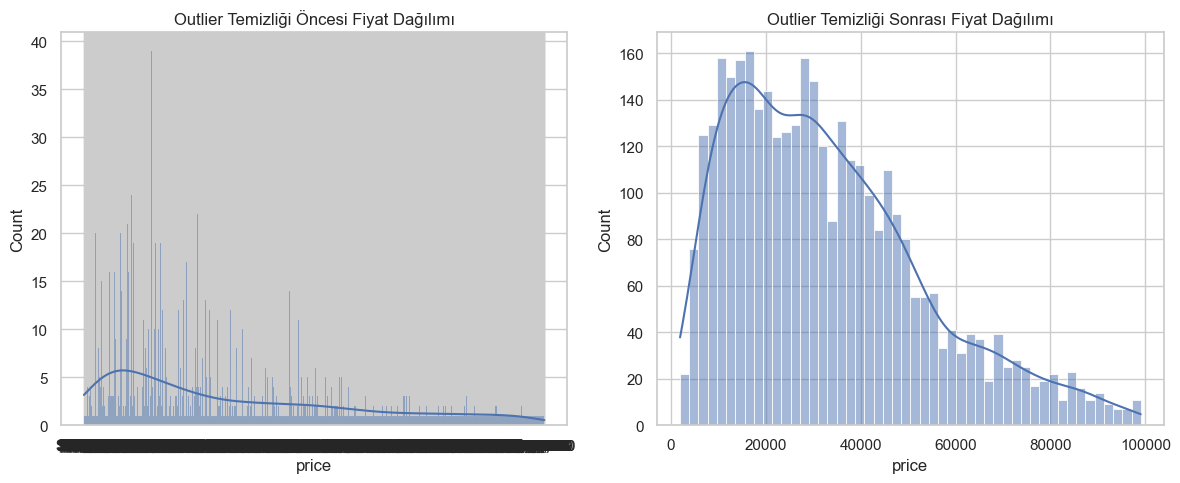

In [188]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_original['price'], bins=50, kde=True)
plt.title("Outlier Temizliği Öncesi Fiyat Dağılımı")

plt.subplot(1, 2, 2)
sns.histplot(df_processed['price'], bins=50, kde=True)
plt.title("Outlier Temizliği Sonrası Fiyat Dağılımı")

plt.tight_layout()
plt.show()


In [148]:
df_processed['Accident_Impact'] = df_processed['accident'].apply(lambda x: 1 if x == 'At least 1 accident or damage reported' else 0)
df_processed['clean_title'] = df_processed['clean_title'].apply(lambda x: 1 if x == 'Yes' else 0)


In [149]:
categorical_columns = ['brand', 'fuel_type', 'transmission_clean', 'is_v_engine', 'turbo', 'dohc','exterior_color', 'interior_color']

for cat_col in categorical_columns:
    encoder = LabelEncoder()
    df_processed[cat_col] = encoder.fit_transform(df_processed[cat_col])


In [150]:
df_processed['Mileage_per_Year'] = df_processed.apply(
    lambda row: row['milage'] / row['car_age'] if row['car_age'] > 0 else row['milage'],
    axis=1
)

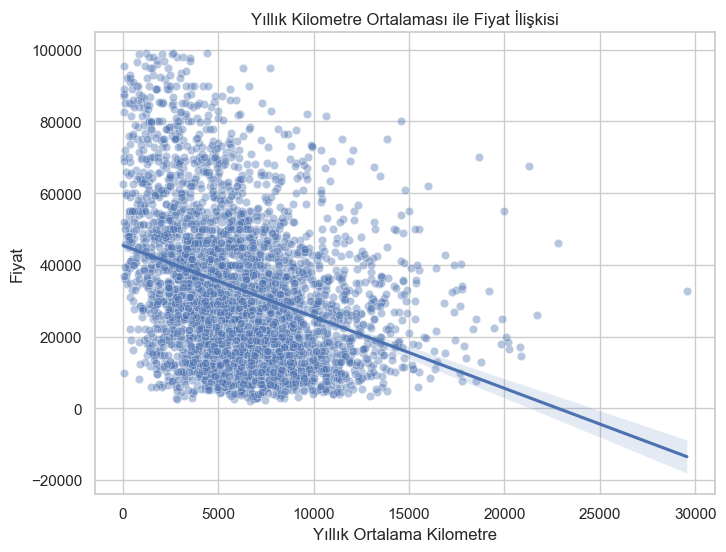

In [186]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=df_processed['Mileage_per_Year'],
    y=df_processed['price'],
    alpha=0.4
)

sns.regplot(
    x=df_processed['Mileage_per_Year'],
    y=df_processed['price'],
    scatter=False
)

plt.xlabel("Yıllık Ortalama Kilometre")
plt.ylabel("Fiyat")
plt.title("Yıllık Kilometre Ortalaması ile Fiyat İlişkisi")
plt.show()


In [151]:
df_processed.drop(['model','accident'], axis = 1, inplace = True)

In [152]:
df_processed.head(10)


,brand,milage,fuel_type,clean_title,price,car_age,hp,engine displacement,is_v_engine,turbo,dohc,transmission_clean,exterior_color,interior_color,Accident_Impact,Mileage_per_Year
0,12,51000,0,1,10300,13,300.000000,3.7,1,0,0,0,0,0,1,3923.076923
1,17,34742,1,1,38005,5,246.700000,3.8,1,0,1,0,6,8,1,6948.400000
2,24,22372,1,1,54598,4,303.659259,3.5,0,0,1,0,1,0,0,5593.000000
3,18,88900,2,1,15500,11,354.000000,3.5,1,0,0,0,0,0,0,8081.818182
4,3,9835,1,1,34999,5,318.831250,2.0,0,0,1,0,9,0,0,1967.000000
5,0,136397,1,1,14798,10,256.595238,2.4,0,0,0,3,8,0,0,13639.700000
6,3,84000,1,1,31000,9,292.000000,2.0,0,0,0,0,1,0,0,9333.333333
8,24,23436,1,1,41927,5,311.000000,3.5,1,0,0,0,0,0,0,4687.200000
9,47,34000,1,1,69950,6,534.000000,3.5,0,0,0,0,0,0,0,5666.666667
10,23,27608,1,1,73897,5,381.039216,3.0,1,0,0,0,9,0,0,5521.600000


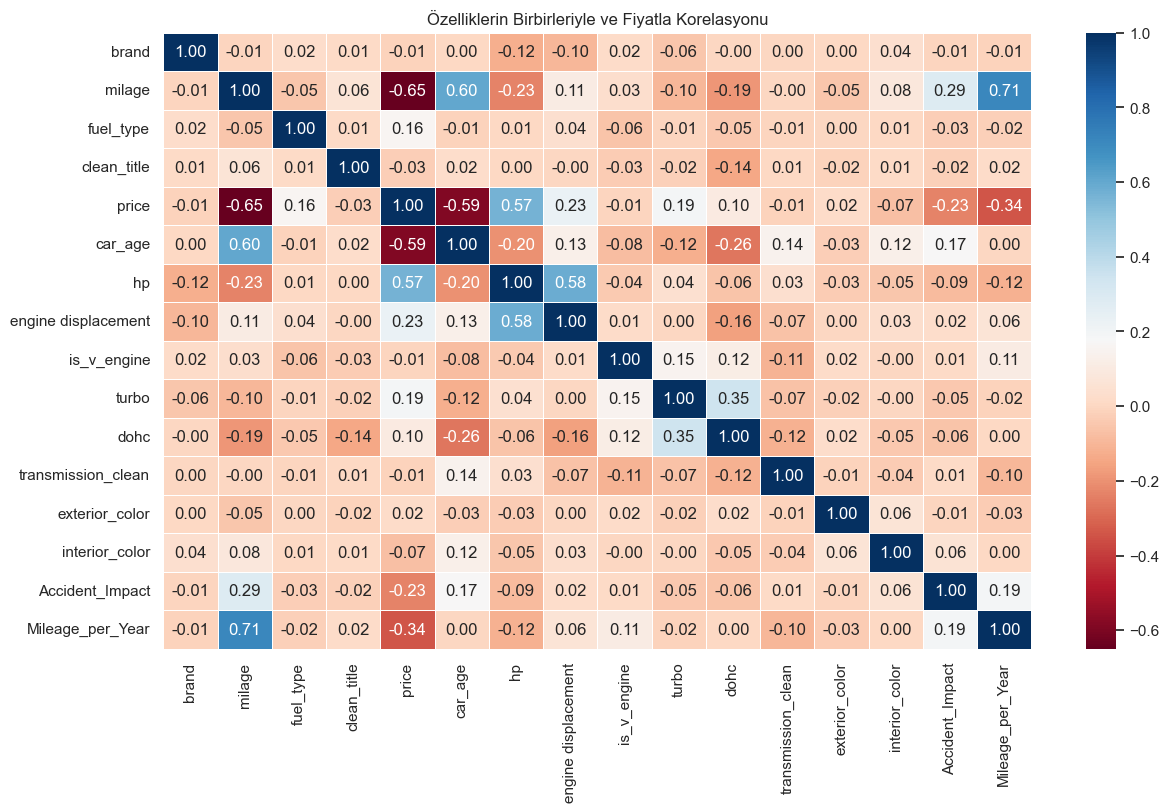

In [153]:
# heatmap
plt.figure(figsize=(14, 8))

corr_matrix = df_processed.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr_matrix, annot=True, cmap='RdBu', fmt=".2f", linewidths=0.5)
plt.title("Özelliklerin Birbirleriyle ve Fiyatla Korelasyonu")
plt.show()

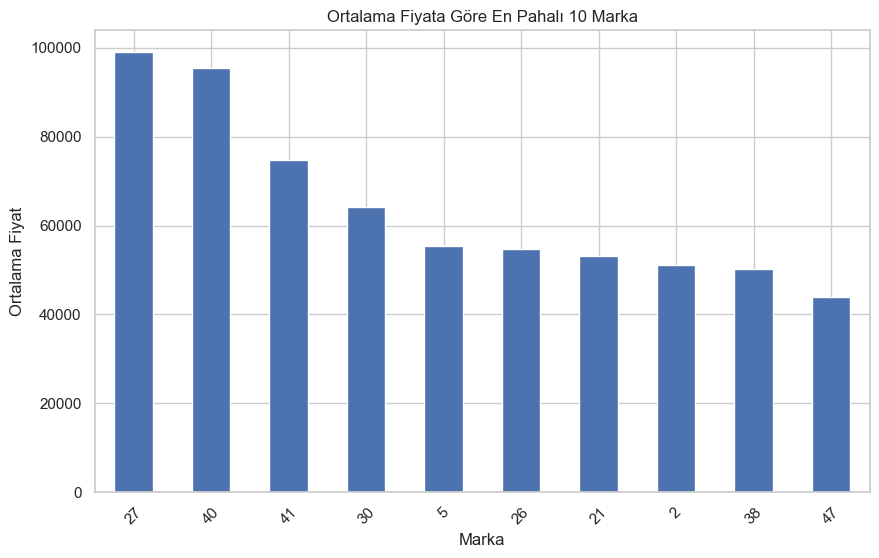

In [189]:
top_brands = (
    df_processed
    .groupby('brand')['price']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
top_brands.plot(kind='bar')
plt.ylabel("Ortalama Fiyat")
plt.xlabel("Marka")
plt.title("Ortalama Fiyata Göre En Pahalı 10 Marka")
plt.xticks(rotation=45)
plt.show()


In [162]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [163]:
# Features
num_features = ['milage', 'car_age', 'hp', 'engine displacement', 'Mileage_per_Year']
cat_features = ['brand', 'fuel_type', 'transmission_clean', 'exterior_color', 'interior_color']
binary_features = ['clean_title', 'Accident_Impact', 'is_v_engine', 'turbo', 'dohc']

X = df_processed[num_features + cat_features + binary_features]
y = df_processed['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Linear Regression Pipeline
linear_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features + binary_features)
    ]
)

linear_model = Pipeline(steps=[
    ('preprocessor', linear_preprocessor),
    ('regressor', LinearRegression())
])

linear_model.fit(X_train, y_train)
y_pred_lr = linear_model.predict(X_test)

print("Linear Regression R2:", r2_score(y_test, y_pred_lr))


Linear Regression R2: 0.7368766539346077


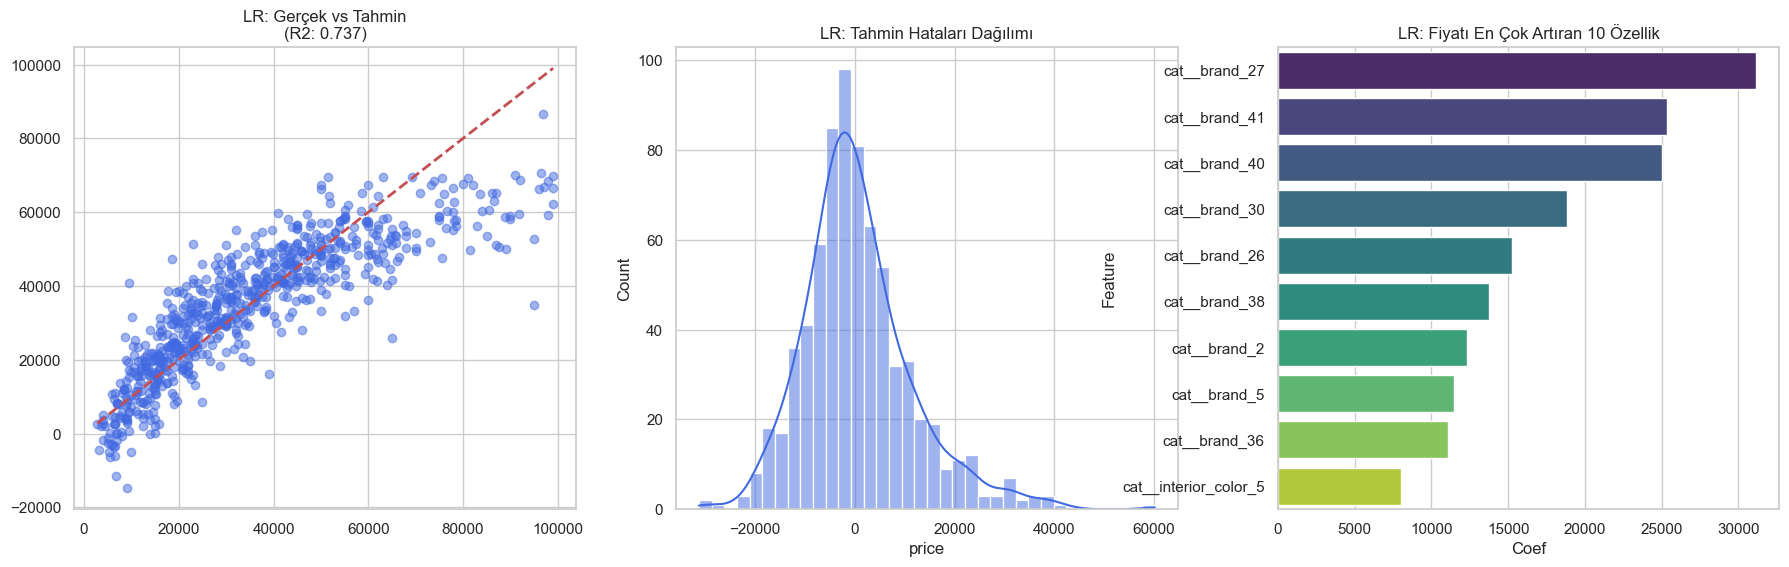

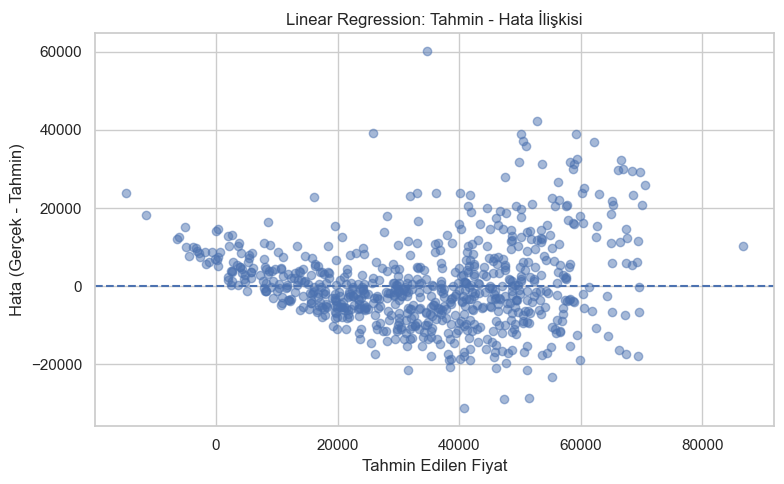

In [191]:
fig, ax = plt.subplots(1, 3, figsize=(22, 6))

# Gerçek vs Tahmin
ax[0].scatter(y_test, y_pred_lr, alpha=0.5, color='royalblue')
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
ax[0].set_title(f"LR: Gerçek vs Tahmin\n(R2: {r2_score(y_test, y_pred_lr):.3f})")

# Hata Dağılımı
sns.histplot(y_test - y_pred_lr, kde=True, ax=ax[1], color='royalblue')
ax[1].set_title("LR: Tahmin Hataları Dağılımı")

# Özellik Önemi
lr_coefs = linear_model.named_steps['regressor'].coef_
lr_features = linear_model.named_steps['preprocessor'].get_feature_names_out()
lr_imp_df = pd.DataFrame({'Feature': lr_features, 'Coef': lr_coefs}).sort_values(by='Coef', ascending=False).head(10)
sns.barplot(
    x='Coef',
    y='Feature',
    hue='Feature',
    data=lr_imp_df,
    ax=ax[2],
    palette='viridis',
    legend=False
)
ax[2].set_title("LR: Fiyatı En Çok Artıran 10 Özellik")

# Residual vs Predicted (Linear Regression)
residuals_lr = y_test - y_pred_lr

residuals_lr = y_test - y_pred_lr

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_lr, residuals_lr, alpha=0.5)
plt.axhline(0, linestyle='--')
plt.xlabel("Tahmin Edilen Fiyat")
plt.ylabel("Hata (Gerçek - Tahmin)")
plt.title("Linear Regression: Tahmin - Hata İlişkisi")

plt.tight_layout()
plt.show()

In [165]:
rf_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_features),
        ('cat', OrdinalEncoder(), cat_features + binary_features)
    ]
)

rf_model = Pipeline(steps=[
    ('preprocessor', rf_preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
print("Random Forest R2:", r2_score(y_test, y_pred_rf))

Random Forest R2: 0.8107578985027972


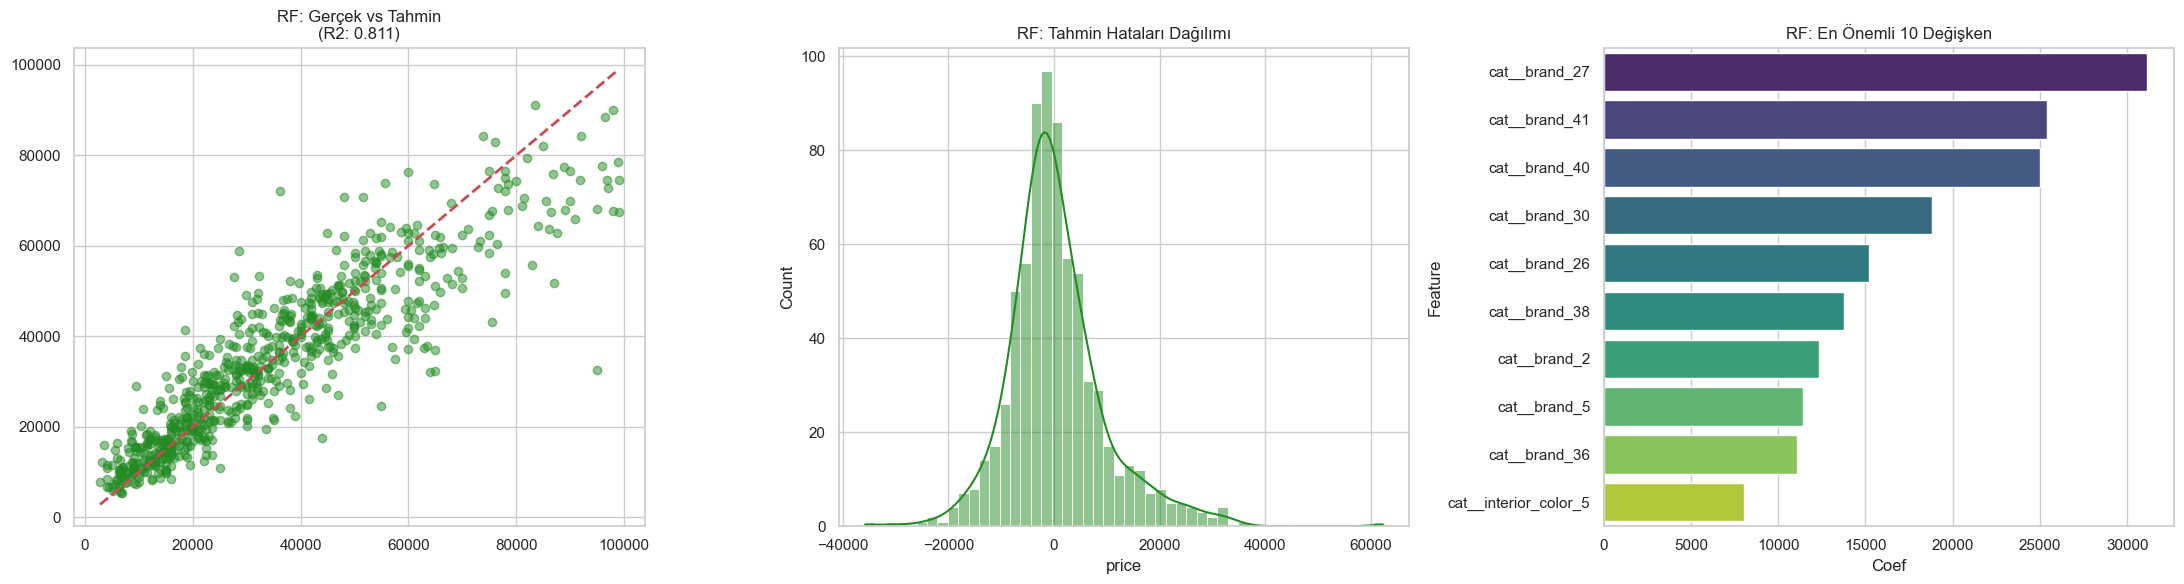

In [169]:
fig, ax = plt.subplots(1, 3, figsize=(22, 6))

# Gerçek vs Tahmin
ax[0].scatter(y_test, y_pred_rf, alpha=0.5, color='forestgreen')
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
ax[0].set_title(f"RF: Gerçek vs Tahmin\n(R2: {r2_score(y_test, y_pred_rf):.3f})")

# Hata Dağılımı
sns.histplot(y_test - y_pred_rf, kde=True, ax=ax[1], color='forestgreen')
ax[1].set_title("RF: Tahmin Hataları Dağılımı")

# Özellik Önemi
rf_importances = rf_model.named_steps['regressor'].feature_importances_
rf_features = rf_model.named_steps['preprocessor'].get_feature_names_out()
rf_imp_df = pd.DataFrame({'Feature': rf_features, 'Importance': rf_importances}).sort_values(by='Importance', ascending=False).head(10)
sns.barplot(
    x='Coef',
    y='Feature',
    hue='Feature',
    data=lr_imp_df,
    ax=ax[2],
    palette='viridis',
    legend=False
)
ax[2].set_title("RF: En Önemli 10 Değişken")

plt.tight_layout()
plt.show()

In [170]:
xgb_model = Pipeline(steps=[
    ('preprocessor', rf_preprocessor),
    ('regressor', XGBRegressor(n_estimators=100, random_state=42, tree_method='hist'))
])

xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
print("XGB R2:", r2_score(y_test, y_pred_xgb))


XGB R2: 0.8413138389587402


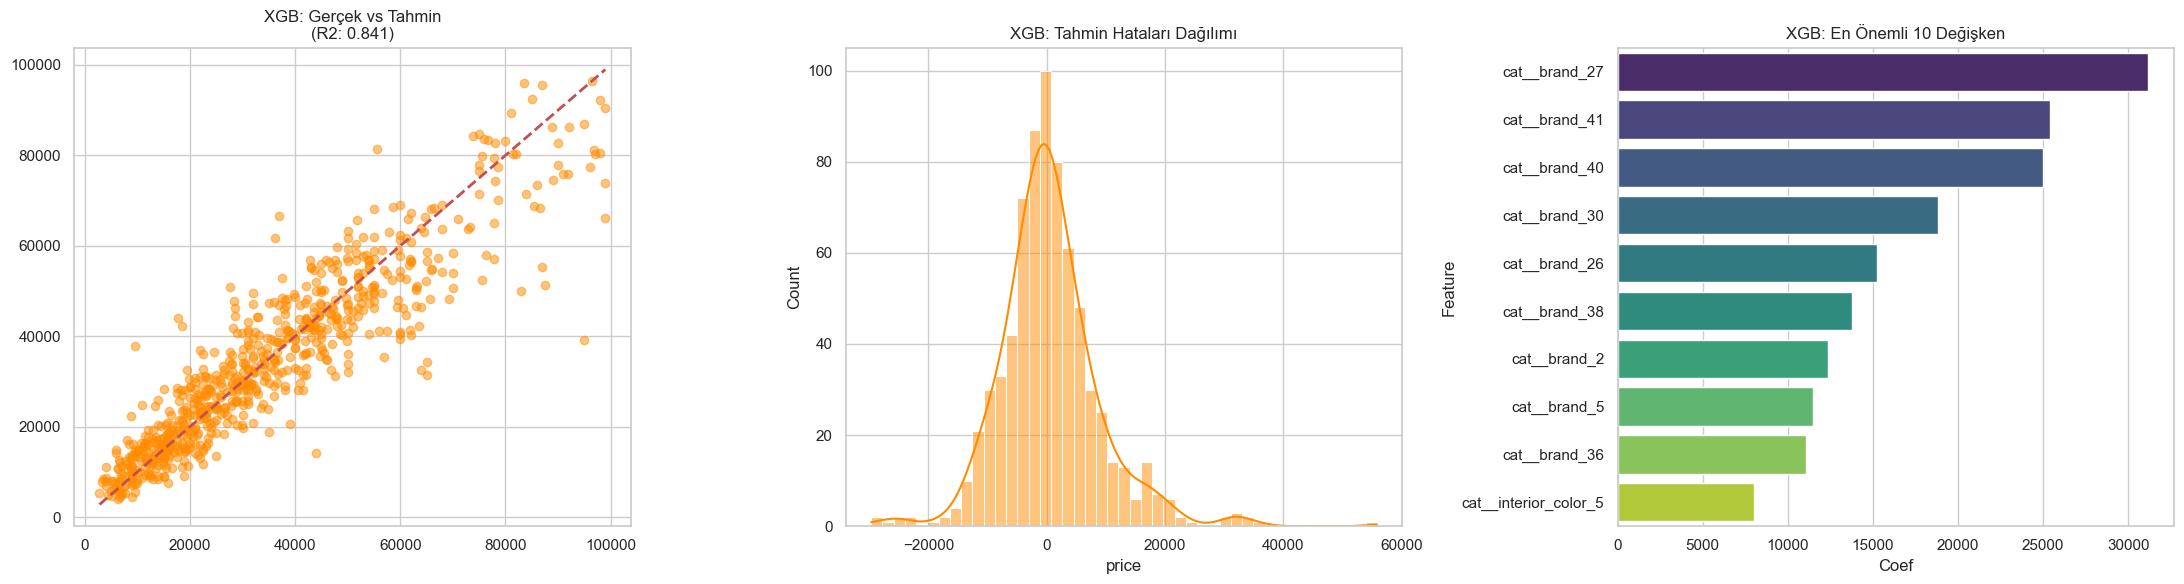

In [173]:
fig, ax = plt.subplots(1, 3, figsize=(22, 6))

 #Gerçek vs Tahmin
ax[0].scatter(y_test, y_pred_xgb, alpha=0.5, color='darkorange')
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
ax[0].set_title(f"XGB: Gerçek vs Tahmin\n(R2: {r2_score(y_test, y_pred_xgb):.3f})")

#Hata Dağılımı
sns.histplot(y_test - y_pred_xgb, kde=True, ax=ax[1], color='darkorange')
ax[1].set_title("XGB: Tahmin Hataları Dağılımı")

# Özellik Önemi
xgb_importances = xgb_model.named_steps['regressor'].feature_importances_
xgb_imp_df = pd.DataFrame({'Feature': rf_features, 'Importance': xgb_importances}).sort_values(by='Importance', ascending=False).head(10)
sns.barplot(
    x='Coef',
    y='Feature',
    hue='Feature',
    data=lr_imp_df,
    ax=ax[2],
    palette='viridis',
    legend=False
)
ax[2].set_title("XGB: En Önemli 10 Değişken")

plt.tight_layout()
plt.show()

In [174]:
df_processed.head()

,brand,milage,fuel_type,clean_title,price,car_age,hp,engine displacement,is_v_engine,turbo,dohc,transmission_clean,exterior_color,interior_color,Accident_Impact,Mileage_per_Year
0,12,51000,0,1,10300,13,300.000000,3.7,1,0,0,0,0,0,1,3923.076923
1,17,34742,1,1,38005,5,246.700000,3.8,1,0,1,0,6,8,1,6948.400000
2,24,22372,1,1,54598,4,303.659259,3.5,0,0,1,0,1,0,0,5593.000000
3,18,88900,2,1,15500,11,354.000000,3.5,1,0,0,0,0,0,0,8081.818182
4,3,9835,1,1,34999,5,318.831250,2.0,0,0,1,0,9,0,0,1967.000000


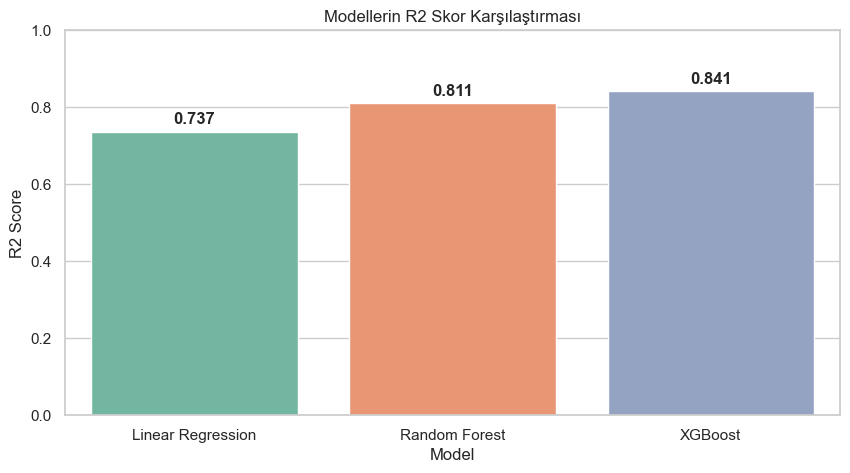

               Model  R2 Score          MAE
0  Linear Regression  0.736877  8043.784281
1      Random Forest  0.810758  6548.394428
2            XGBoost  0.841314  5993.354004


In [182]:
# 5. Tüm Modellerin Performans Özeti
compare_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost'],
    'R2 Score': [r2_score(y_test, y_pred_lr), r2_score(y_test, y_pred_rf), r2_score(y_test, y_pred_xgb)],
    'MAE': [mean_absolute_error(y_test, y_pred_lr), mean_absolute_error(y_test, y_pred_rf), mean_absolute_error(y_test, y_pred_xgb)]
})

plt.figure(figsize=(10, 5))
sns.barplot(
    x='Model',
    y='R2 Score',
    hue='Model',
    data=compare_df,
    palette='Set2',
    legend=False
)
plt.ylim(0, 1)
plt.title("Modellerin R2 Skor Karşılaştırması")
for i, val in enumerate(compare_df['R2 Score']):
    plt.text(i, val + 0.02, f'{val:.3f}', ha='center', fontweight='bold')
plt.show()

print(compare_df)

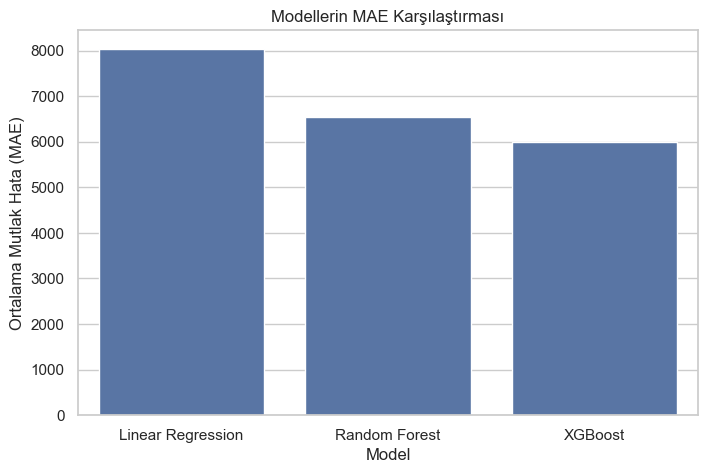

In [192]:
error_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost'],
    'MAE': [
        mean_absolute_error(y_test, y_pred_lr),
        mean_absolute_error(y_test, y_pred_rf),
        mean_absolute_error(y_test, y_pred_xgb)
    ]
})

plt.figure(figsize=(8, 5))
sns.barplot(
    x='Model',
    y='MAE',
    data=error_df
)
plt.title("Modellerin MAE Karşılaştırması")
plt.ylabel("Ortalama Mutlak Hata (MAE)")
plt.show()
